In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import scienceplots
from network_creation.stats.er_payoff import expected_aggregate_payoff

plt.style.use("science")

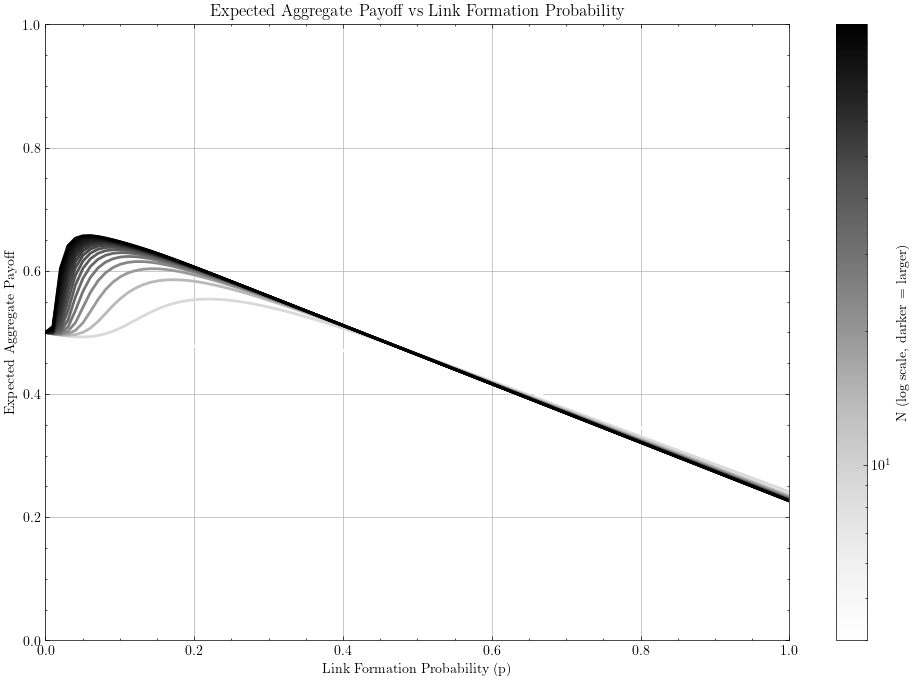

In [2]:
N_values = np.arange(4, 100, 5, dtype=int)
p_values = np.linspace(0, 1, 100, dtype=float)

results = np.zeros((len(N_values), len(p_values)))
for i, N in enumerate(N_values):
    for j, p in enumerate(p_values):
        results[i, j] = expected_aggregate_payoff(N, 0.5, p, 0.9)

fig, ax = plt.subplots(figsize=(12, 8))

norm = LogNorm(vmin=N_values.min(), vmax=N_values.max())
cmap = plt.cm.Greys

for i, N in enumerate(N_values):
    ax.plot(p_values, results[i], color=cmap(norm(N)), linewidth=2)

ax.set_title("Expected Aggregate Payoff vs Link Formation Probability")
ax.set_xlabel("Link Formation Probability (p)")
ax.set_ylabel("Expected Aggregate Payoff")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(True)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, label="N (log scale, darker = larger)")

plt.show()

In [3]:
v_k = np.linspace(0.001, 0.999, 100)
delta = np.linspace(0.001, 0.999, 100)
N = 50

grid_results = np.array(
    [[expected_aggregate_payoff(N, v, None, d) for d in delta] for v in v_k],
    dtype=float,
)
results_max_payoff = grid_results[..., 0]
results_p = grid_results[..., 1]

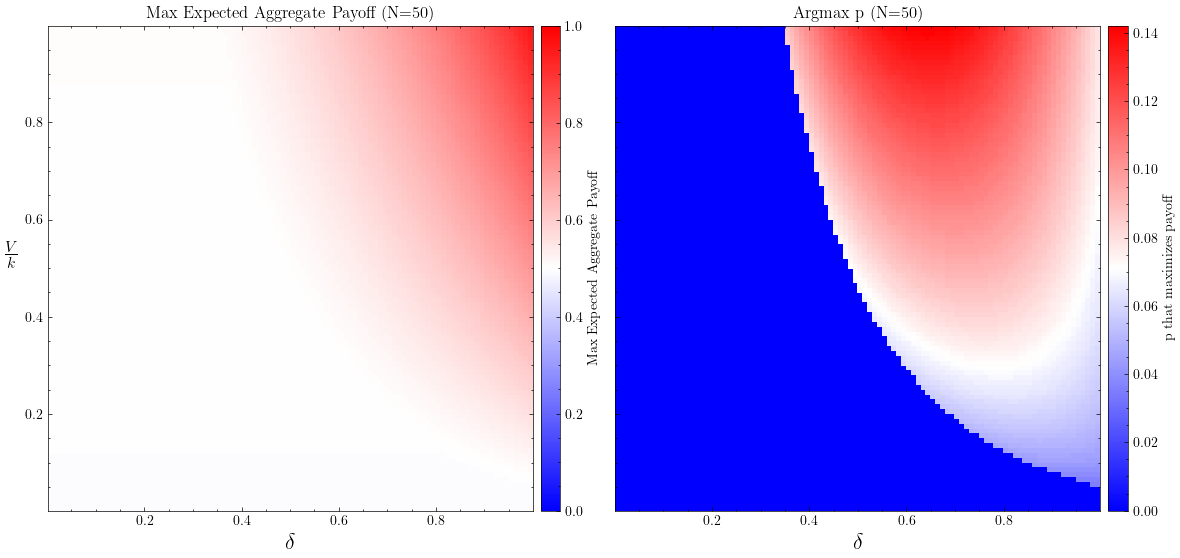

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 6), sharex=True, sharey=True)

im0 = ax[0].imshow(
    results_max_payoff,
    origin="lower",
    aspect="equal",
    extent=(delta.min(), delta.max(), v_k.min(), v_k.max()),
    cmap="bwr",
    vmin=0.0,
    vmax=1.0,
)
ax[0].set_box_aspect(1)
div0 = make_axes_locatable(ax[0])
cax0 = div0.append_axes("right", size="4%", pad=0.08)
fig.colorbar(im0, cax=cax0, label="Max Expected Aggregate Payoff")

im1 = ax[1].imshow(
    results_p,
    origin="lower",
    aspect="equal",
    extent=(delta.min(), delta.max(), v_k.min(), v_k.max()),
    cmap="bwr",
)
ax[1].set_box_aspect(1)
div1 = make_axes_locatable(ax[1])
cax1 = div1.append_axes("right", size="4%", pad=0.08)
fig.colorbar(im1, cax=cax1, label="p that maximizes payoff")
 
ax[0].set_title(f"Max Expected Aggregate Payoff (N={N})")
ax[1].set_title(f"Argmax p (N={N})")
ax[0].set_xlabel(r"$\delta$", size=16)
ax[1].set_xlabel(r"$\delta$", size=16)
ax[0].set_ylabel(r"$\frac{V}{k}$", size=16, rotation=0, labelpad=10)

plt.tight_layout()
plt.show()